# 심화 04 · 커널 모양·크기·반복 횟수와 잡음 제거·객체 손실

`main.py`의 H04를 기준으로 같은 이진 이미지에 Opening을 적용합니다. 모양 2종 × 크기 2종 × 반복 횟수 2종, 총 8개 조합을 비교합니다.

필요 패키지: `opencv-python`, `numpy`, `pandas`, `matplotlib`, `IPython`. 프로젝트 내부에서 패키지가 설치된 커널로 순서대로 실행하세요. 원본은 보존하며 `outputs/` 결과는 다시 생성합니다.

## 1. 연산과 커널을 구분하기

`getStructuringElement(shape, size)`의 `shape`는 커널 모양이고, `morphologyEx(src, op, kernel)`의 `op`는 연산 종류입니다. 따라서 **`op=cv2.MORPH_OPEN`**을 지정해야 합니다. `MORPH_RECT` 값 0을 op에 넣으면 침식이 실행됩니다. `MORPH_ELLIPSE` 값 2가 Opening 값과 우연히 같아도 서로 다른 용도의 상수입니다.

Opening은 침식 후 팽창입니다. `iterations=2`는 침식 2회 후 팽창 2회를 뜻하며, Opening 전체를 단순히 두 번 호출하는 것과 다릅니다.

### 실행 전 예상

커널이 커지거나 iterations가 늘어나면 작은 전경이나 가느다란 구조가 침식 단계에서 사라질 가능성이 커집니다. 이후 팽창을 해도 완전히 사라진 구조는 복구되지 않습니다. 다만 모양과 크기, 입력 형상에 따라 결과가 같을 수도 있으므로 실제 표와 이미지를 확인합니다.

In [1]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

notebook_start = Path.cwd().resolve()
project = next((p for p in [notebook_start, *notebook_start.parents]
                if (p / "20261104/03_심화/04_morphology/main.py").is_file()), None)
if project is None:
    raise FileNotFoundError("프로젝트 내부에서 실행하세요.")
exercise = project / "20261104/03_심화/04_morphology"


## 2. 현재 구현 실행

입력 그레이스케일 → 임계값 127 이진화 → 각 커널로 Opening → 전경 픽셀 수·배경 제외 연결요소 수 기록 순서입니다. 연결요소는 8방향 인접 기준입니다. 노트북에서는 `__file__` 경로만 `exercise`로 대체했습니다.

In [2]:
from pathlib import Path
import os
import cv2
import numpy as np

# 제공 코드: 어느 작업 폴더에서 실행해도 현재 파일 옆의 입력을 읽습니다.
# OpenCV에는 영문 상대 경로를 전달합니다. 원본 파일은 덮어쓰지 않습니다.
os.chdir(exercise)

import csv
import json
from time import perf_counter
Path("outputs").mkdir(exist_ok=True)

gray=cv2.imread("../data/objects.png",0)
_, binary=cv2.threshold(gray,127,255,cv2.THRESH_BINARY)
rows=[]
for shape_name,shape in [("rect",cv2.MORPH_RECT),("ellipse",cv2.MORPH_ELLIPSE)]:
    for size in [3,5]:
        for iterations in [1,2]:
            kernel=cv2.getStructuringElement(shape,(size,size))
            # >>> TODO H04
            # 현재 kernel과 iterations를 사용하여 binary에 Opening을 적용하세요.
            result=cv2.morphologyEx(
                src=binary,
                op=cv2.MORPH_OPEN,
                kernel=kernel,
                iterations=iterations
            )
            # <<< TODO H04
            count, labels, stats, centroids=cv2.connectedComponentsWithStats(result,connectivity=8)
            name=f"{shape_name}_{size}_{iterations}"
            cv2.imwrite(f"outputs/{name}.png",result)
            rows.append([name,int(np.count_nonzero(result)),count-1])
with open("outputs/morphology.csv","w",encoding="utf-8-sig",newline="") as f:
    w=csv.writer(f);w.writerow(["setting","foreground_pixels","components_without_background"]);w.writerows(rows)
print(rows)


[['rect_3_1', 14133, 3], ['rect_3_2', 14133, 3], ['rect_5_1', 14133, 3], ['rect_5_2', 14133, 3], ['ellipse_3_1', 14129, 3], ['ellipse_3_2', 14113, 3], ['ellipse_5_1', 14119, 3], ['ellipse_5_2', 14087, 3]]


## 3. 실제 커널 배열

사각 커널은 모서리를 포함한 모든 칸이 1입니다. 타원 커널은 크기에 따라 이산 격자 모양이 달라집니다. 3×3 타원은 십자 모양으로 표현됩니다. 1인 위치가 형태학 연산에 참여합니다.

In [3]:
kernel_records = []
for shape_name, shape in [("rect", cv2.MORPH_RECT), ("ellipse", cv2.MORPH_ELLIPSE)]:
    for size in [3, 5]:
        k = cv2.getStructuringElement(shape, (size, size))
        kernel_records.append({"모양": shape_name, "크기": f"{size}×{size}",
                               "활성 칸 수": int(k.sum()), "배열": k.tolist()})
        print(f"{shape_name} {size}×{size}")
        print(k)
display(pd.DataFrame(kernel_records).drop(columns="배열"))

rect 3×3
[[1 1 1]
 [1 1 1]
 [1 1 1]]
rect 5×5
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]
ellipse 3×3
[[0 1 0]
 [1 1 1]
 [0 1 0]]
ellipse 5×5
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


,모양,크기,활성 칸 수
0,rect,3×3,9
1,rect,5×5,25
2,ellipse,3×3,5
3,ellipse,5×5,17


## 4. 원본 연결요소와 측정 기준

별도의 정답 마스크가 없으므로 의미상 잡음과 실제 객체를 크기만으로 확정할 수 없습니다. 이 예제에서는 **면적 1픽셀의 고립점을 잡음 후보**, **그보다 큰 연결요소를 관찰 대상 객체**로 분리합니다. 이는 이 입력을 분석하기 위한 기준이며 일반적인 객체 검출 규칙은 아닙니다.

아래 표로 원본의 위치와 면적을 확인합니다. 잡음 후보 제거 수와 관찰 객체의 소실 픽셀 수는 따로 측정합니다.

In [4]:
n, original_labels, original_stats, original_centroids = cv2.connectedComponentsWithStats(binary, connectivity=8)
component_rows = []
for label in range(1, n):
    x, y, w, h, area = original_stats[label].tolist()
    component_rows.append({"label": label, "x": x, "y": y, "width": w, "height": h,
                           "area": area, "구분": "잡음 후보 (1픽셀)" if area == 1 else "관찰 객체"})
components = pd.DataFrame(component_rows)
display(components)
noise_labels = components.loc[components["area"] == 1, "label"].tolist()
object_labels = components.loc[components["area"] > 1, "label"].tolist()
noise_mask = np.isin(original_labels, noise_labels)
object_mask = np.isin(original_labels, object_labels)
print("원본 전경:", int(np.count_nonzero(binary)), "연결요소:", n - 1)
print("잡음 후보:", len(noise_labels), "관찰 객체:", len(object_labels))

,label,x,y,width,height,area,구분
0,1,12,13,1,1,1,잡음 후보 (1픽셀)
1,2,130,30,1,1,1,잡음 후보 (1픽셀)
2,3,35,50,66,91,5997,관찰 객체
3,4,160,65,81,81,5009,관찰 객체
4,5,280,90,1,1,1,잡음 후보 (1픽셀)
5,6,165,175,101,31,3131,관찰 객체
6,7,20,200,1,1,1,잡음 후보 (1픽셀)
7,8,300,220,1,1,1,잡음 후보 (1픽셀)


원본 전경: 14142 연결요소: 8
잡음 후보: 5 관찰 객체: 3


## 5. 8개 설정의 잡음 제거와 객체 손실 비교

- **제거된 잡음 후보 수**: 원본 1픽셀 고립점 중 출력에서 사라진 수입니다.
- **객체 손실 픽셀 수**: 원본의 관찰 객체 영역에서 사라진 전경 픽셀 수입니다.
- **완전 소실 객체 수**: 원본 관찰 객체와 겹치는 출력 픽셀이 하나도 남지 않은 경우를 셉니다.

전경 감소를 모두 잡음 제거로 해석하지 않습니다. 연결요소 수가 같아도 객체 경계나 가느다란 부분이 사라질 수 있습니다.

In [5]:
summary_rows = []
retention_rows = []
results = {}
for shape_name, shape in [("rect", cv2.MORPH_RECT), ("ellipse", cv2.MORPH_ELLIPSE)]:
    for size in [3, 5]:
        for iterations in [1, 2]:
            k = cv2.getStructuringElement(shape, (size, size))
            out = cv2.morphologyEx(binary, cv2.MORPH_OPEN, k, iterations=iterations)
            setting = f"{shape_name}_{size}_{iterations}"
            results[setting] = out
            remaining = out > 0
            assert not np.any(remaining & (binary == 0))
            vanished = 0
            for label in object_labels:
                ref = original_labels == label
                before = int(ref.sum())
                after = int(np.count_nonzero(ref & remaining))
                vanished += int(after == 0)
                retention_rows.append({"설정": setting, "객체 label": label,
                                       "원본 면적": before, "남은 면적": after,
                                       "손실 픽셀": before - after,
                                       "보존율 (%)": round(after / before * 100, 3)})
            count = cv2.connectedComponentsWithStats(out, connectivity=8)[0] - 1
            summary_rows.append({"모양": shape_name, "크기": size, "iterations": iterations,
                                 "전경 픽셀 수": int(remaining.sum()), "연결요소 수": count,
                                 "원본 대비 전경 감소": int(np.count_nonzero(binary)) - int(remaining.sum()),
                                 "제거된 잡음 후보 수": int(np.count_nonzero(noise_mask & ~remaining)),
                                 "객체 손실 픽셀 수": int(np.count_nonzero(object_mask & ~remaining)),
                                 "완전 소실 객체 수": vanished})
summary = pd.DataFrame(summary_rows)
retention = pd.DataFrame(retention_rows)
display(summary)
display(retention.pivot(index="설정", columns="객체 label", values="손실 픽셀"))

,모양,크기,iterations,전경 픽셀 수,연결요소 수,원본 대비 전경 감소,제거된 잡음 후보 수,객체 손실 픽셀 수,완전 소실 객체 수
0,rect,3,1,14133,3,9,5,4,0
1,rect,3,2,14133,3,9,5,4,0
2,rect,5,1,14133,3,9,5,4,0
3,rect,5,2,14133,3,9,5,4,0
4,ellipse,3,1,14129,3,13,5,8,0
5,ellipse,3,2,14113,3,29,5,24,0
6,ellipse,5,1,14119,3,23,5,18,0
7,ellipse,5,2,14087,3,55,5,50,0


객체 label,3,4,6
설정,,,
ellipse_3_1,4,0,4
ellipse_3_2,12,0,12
ellipse_5_1,8,2,8
ellipse_5_2,24,2,24
rect_3_1,0,4,0
rect_3_2,0,4,0
rect_5_1,0,4,0
rect_5_2,0,4,0


## 6. 출력 이미지와 사라진 픽셀

위쪽은 Opening 결과, 아래쪽은 **원본 전경 중 사라진 위치**입니다. 고립점만 사라졌는지, 원형 경계·모서리·작은 구조도 함께 사라졌는지 확인합니다.

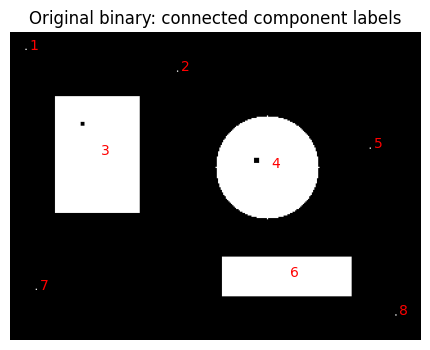

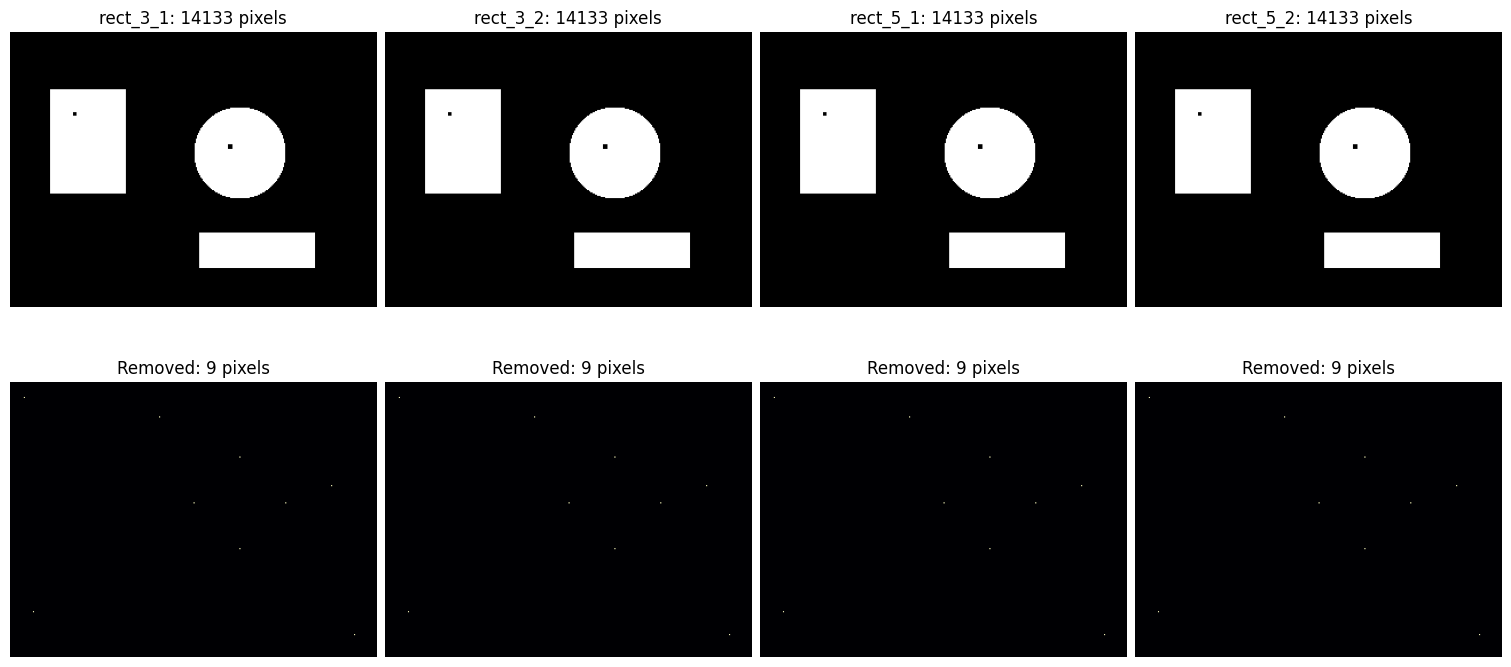

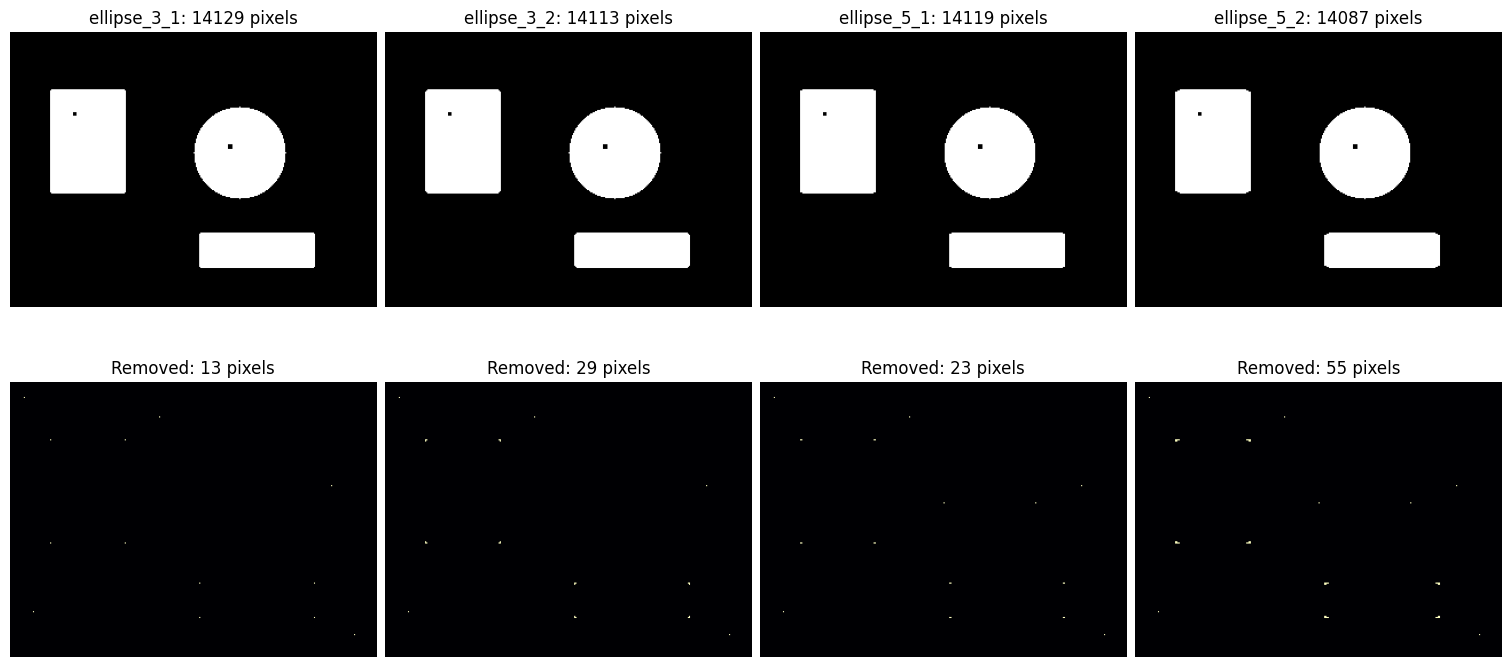

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.imshow(binary, cmap="gray", vmin=0, vmax=255)
for label in range(1, n):
    x, y = original_centroids[label]
    ax.text(x + 3, y, str(label), color="red", fontsize=10)
ax.set_title("Original binary: connected component labels")
ax.axis("off")
plt.show()
for shape_name in ["rect", "ellipse"]:
    fig, axes = plt.subplots(2, 4, figsize=(15, 7), constrained_layout=True)
    for col, (size, iterations) in enumerate([(3, 1), (3, 2), (5, 1), (5, 2)]):
        setting = f"{shape_name}_{size}_{iterations}"
        out = results[setting]
        removed = (binary > 0) & (out == 0)
        axes[0, col].imshow(out, cmap="gray", vmin=0, vmax=255)
        axes[0, col].set_title(f"{setting}: {np.count_nonzero(out)} pixels")
        axes[1, col].imshow(removed, cmap="magma", vmin=0, vmax=1)
        axes[1, col].set_title(f"Removed: {int(removed.sum())} pixels")
        for row in range(2): axes[row, col].axis("off")
    plt.show()

## 7. 잡음 제거와 객체 손실 해석

이 입력에서는 모든 조합에서 고립된 1픽셀 점 5개가 제거되고 관찰 대상 객체 3개는 남습니다. **완전 소실 객체 0개는 객체 정보 손실 0을 뜻하지 않습니다.** 사각 커널에서는 관찰 객체의 픽셀이 4개씩, 타원 커널에서는 설정에 따라 8~50개 사라집니다. 두 모양 모두 객체 경계의 일부 손실이 있습니다.

- **모양 비교:** 같은 3×3이라도 사각과 타원의 활성 위치가 다르므로 물체 모양에 대한 반응이 달라집니다. 사각 커널은 이 입력의 사각형과 원형 등 구조에서, 타원 커널과 다른 경계 보존 결과를 만듭니다.
- **크기 비교:** 사각 3·5 조합은 이 입력에서 같은 전경 수를 보입니다. 크기를 바꿨다고 항상 수치가 달라지는 것은 아닙니다. 타원 커널에서는 5×5가 3×3보다 더 많은 객체 픽셀을 제거합니다.
- **iterations 비교:** 타원 커널은 2회에서 1회보다 더 많은 객체 픽셀을 제거합니다. 사각 커널은 이번 입력에서는 차이가 없습니다. 따라서 반복 횟수 효과도 입력 형상과 함께 읽어야 합니다.

### 작은 실제 객체에 대한 위험

이 이미지의 고립점을 잡음 후보로 분류한 것은 분석상의 가정입니다. 실제 과제에서 같은 1픽셀 점이 중요한 작은 객체라면, 동일한 제거 결과가 곧 객체 손실입니다. 이 입력에는 별도로 라벨링된 작은 실제 객체가 없으므로 작은 실제 객체의 손실률을 측정했다고 주장할 수 없습니다.

작은 결함, 가느다란 선, 문자 획 등이 침식 단계에서 끊기거나 사라지면 이후 팽창으로 원래 정보가 복구되지 않을 수 있습니다. 다음 모델의 입력으로 사용하면 작은 대상의 누락, 모양·면적 변화, 연결 구조 변화로 이어질 수 있습니다. 검은 구멍을 채우는 목적이라면 Opening과 다른 연산인 Closing을 별도로 검토해야 합니다.

설정의 선택은 잡음과 보존할 실제 객체의 크기·형상, 후속 과제의 요구에 따라 판단합니다. 여기서는 특정 설정을 추천하거나 순위를 정하지 않습니다.

## 8. 저장 결과 검증

현재 코드가 저장한 CSV·PNG를 노트북에서 직접 계산한 Opening 결과와 비교합니다. README의 숫자를 복사하지 않습니다.

In [7]:
recorded = pd.read_csv("outputs/morphology.csv")
assert len(recorded) == len(results) == 8
for row in recorded.itertuples(index=False):
    computed = results[row.setting]
    saved = cv2.imread(f"outputs/{row.setting}.png", cv2.IMREAD_GRAYSCALE)
    assert np.array_equal(computed, saved)
    assert np.count_nonzero(computed) == row.foreground_pixels
    assert cv2.connectedComponentsWithStats(computed, connectivity=8)[0] - 1 == row.components_without_background
assert (summary["원본 대비 전경 감소"] == summary["제거된 잡음 후보 수"] + summary["객체 손실 픽셀 수"]).all()
print("검증 통과: 8개 조합의 Opening·CSV·저장 이미지·손실 분해 일치")
os.chdir(notebook_start)

검증 통과: 8개 조합의 Opening·CSV·저장 이미지·손실 분해 일치
